# Importações

In [1]:
#!pip install swig                                                              # Instala pacotes necessários para o uso do Gym
#!pip install gymnasium[box2d]                                                  # Instala pacotes necessários para o uso do Gym
import gymnasium as gym                                                         # Importa a biblioteca do gymnasium
import numpy as np                                                              # Importa a biblioteca do numpy
import heapq                                                                    # Importa a biblioteca da pilha
import matplotlib.pyplot as plt                                                 # Importa a biblioteca Matplotlib para visualização de dados
import imageio                                                                  # Importa a biblioteca imageio para ler arquivos de imagem
from IPython.display import display, Image                                      # Importa as funções display para exibir objetos no colab e Image para carregar imagens de arquivos

# Funções auxiliares e do A* e configuração do ambiente

In [2]:
# --- Configuração do ambiente determinístico ---
mapa = ["FFFFFFFS",                                                             # Desenho do mapa do ambiente
        "FHFHHHHH",                                                             # F é a parte congelada onde se pode andar
        "FHFFHFFF",                                                             # H é a parte com buracos onde não se pode andar
        "FHHFFFHF",                                                             # S é a posição inicial e G é a posição final
        "FHFHHHFF",
        "FHFFFHFH",
        "FHFHFHHH",
        "FFFHFFFG"]
n_rows = 8                                                                      # Número de linhas do mapa
n_cols = 8                                                                      # Número de colunas do mapa
env = gym.make("FrozenLake-v1", desc=mapa, is_slippery=False, render_mode="rgb_array") # Cria o mapa
env.reset()                                                                     # Reinicia o mapa
frames = []                                                                     # Lista de frames para a animação
custo_mov = 1                                                                   # Custo de cada movimento

# --- Funções auxiliares do A* ---
def neighbors(pos):                                                             # Função que retorna as posições adjacentes a uma dada posição do mapa
    moves = [(-1,0), (1,0), (0,-1), (0,1)]                                      # Esq, dir, cima, baixo
    result = []                                                                 # Lista de posições possíveis
    for dx, dy in moves:                                                        # Percorre as posições possíveis
        nx, ny = pos[0] + dx, pos[1] + dy                                       # Posição final após o movimento
        if 0 <= nx < n_rows and 0 <= ny < n_cols:                               # Se a nova posição está dento dos limites do mapa
            if mapa[nx][ny] != 'H':                                             # Verifica se a nova posição evita buracos
                result.append((nx, ny))                                         # Adiciona a nova posição a lista de posições possíveis
    return result                                                               # Retorna a lista de posições possíveis

def find_pos(letra):                                                            # Função que localiza uma posição única no mapa
    for i in range(n_rows):                                                     # Percorre as linhas do mapa
        for j in range(n_cols):                                                 # Percorre as colunas do mapa
            if mapa[i][j] == letra:                                             # Verifica se a posição atual é a posição desejada
                return (i, j)                                                   # Se sim, retorna a posição

def heuristic(a, b):                                                            # Função heurística h() que calcula a estimativa de custo entre dois pontos do mapa
    return abs(a[0] - b[0]) + abs(a[1] - b[1])                                  # Distância de Manhattan

def cost_function(acc_cost, a, b):                                              # Função de custo de real g() desde o inicio e levando em consideração o custo entre pontos adjacentes.
    if a[0]==b[0] and a[1]==b[1]:                                               # No caso desse problema, sempre é 1, ou zero caso o ponto de origem e destino sejam o mesmo, mas para
      return 0 + acc_cost                                                       # outros problemas, pode ser necessário alterar essa função tabelando o custo entre as posições do mapa.
    else:                                                                       # retorna o custo até aqui mais o custo desse movimento entre esses dois pontos do mapa
      return custo_mov + acc_cost

def a_star(start, goal):                                                        # implementação da função A*
    f = cost_function(0, start, start) + heuristic(start, goal)                 # Calcula a estimativa de custo inicial
    heap = [(f, cost_function(0, start, start), start, [])]                     # Adiciona na pilha o primeiro dado
    visited = set()                                                             # Cria a lista de nós visitados
    while heap:                                                                 # Enquanto existirem elementos na pilha
        f, cost, current, path = heapq.heappop(heap)                            # Desempilha
        if current in visited:                                                  # Verifica se o nó já foi visitado (se está na lista de visitados)
            continue                                                            # Se sim, passa para o próximo elemento da pilha
        path = path + [current]                                                 # Se não, adiciona o nó atual ao path
        if current == goal:                                                     # Verifica se o nó atual é o objetivo
            return path                                                         # Se sim, retorna o caminho até o objetivo
        visited.add(current)                                                    # Adiciona o nó atual à lista de visitados
        for neighbor in neighbors(current):                                     # Para cada vizinho do nó atual (caminhos possíveis)
            f = cost_function(cost, neighbor, current) + heuristic(neighbor, goal) # Calcula o custo total desse nó vizinho
            heapq.heappush(heap, (f, cost_function(cost, neighbor, current), neighbor, path)) # Adiciona o novo nó a pilha
    return None                                                                 # Se não encotrar uma solução, retorna nada

# Funções auxiliares para o Gym

In [3]:
def to_action(curr, next):                                                      # Função que mapeia posições para ações do Gym
    dx = next[0] - curr[0]
    dy = next[1] - curr[1]
    if dx == -1: return 3  # cima
    if dx == 1: return 1   # baixo
    if dy == -1: return 0  # esquerda
    if dy == 1: return 2   # direita

# Código Principal

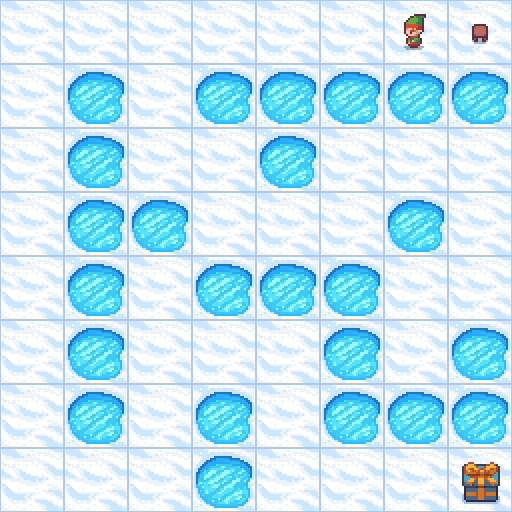

In [5]:
start_pos = find_pos('S')                                                       # Localiza a posição inicial no mapa
goal_pos = find_pos('G')                                                        # Localiza a posição final no mapa

path = a_star(start_pos, goal_pos)                                              # Executar o A* da posição inicial ao objetivo e retorna o caminho encontrado

# Movimenta o agente conforme o caminho encontrado
env.reset()
for i in range(1, len(path)):                                                   # Executar todas as ações do caminho
    action = to_action(path[i-1], path[i])                                      # Determina a ação tomada entre duas posições do caminho
    env.step(action)                                                            # Executa a ação no ambiente
    frames.append(env.render())                                                 # Adiciona a imagem atual do mapa à lista de frames
env.close()                                                                     # Fecha o ambiente

# Criar e exibir GIF do movimento do agente no ambiente
imageio.mimsave("Walk.gif", frames, duration=0.5)                               # Gera um gif a partir das imagens geradas de todas as tentativas
display(Image(filename="Walk.gif"))                                             # Exibe o gif gerado